# 06 – Parkinson's Dataset: Cross-Domain Group-Aware Validation

## Research question
Does keeping all recordings from the same person together during validation change the estimated classification performance on a second scientific dataset?

This notebook is a **methodological cross-domain demonstration**. It compares:
- Random row-level stratified cross-validation.
- Subject-grouped stratified cross-validation.

It uses the UCI Parkinson's voice dataset. Multiple recordings can come from the same participant, so the participant identifier is used as the group.

**Important:** This is a research-methods demonstration, not a medical diagnostic tool. Results must not be used to diagnose or make decisions about any person.


## 1. Imports and dataset location

The notebook first checks common Kaggle input locations for a CSV. If it cannot find one, it attempts to download the original UCI `parkinsons.data` file. If Kaggle internet access is disabled, upload the dataset as a Kaggle input and set `DATA_PATH` to its path.


In [13]:
import os
import glob
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import (
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, brier_score_loss,
    confusion_matrix, classification_report
)

warnings.filterwarnings("ignore")

# If you uploaded a CSV to Kaggle, put its exact path here.
# Leave as None to search Kaggle input folders and then try the UCI source.
DATA_PATH = None

UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/parkinsons/parkinsons.data"

SEEDS = [42]
N_SPLITS = 5
THRESHOLD = 0.50

print("Setup complete.")


Setup complete.


## 2. Load the Parkinson's dataset

In [14]:
def locate_dataset():
    if DATA_PATH is not None:
        if not os.path.exists(DATA_PATH):
            raise FileNotFoundError(f"DATA_PATH does not exist: {DATA_PATH}")
        return DATA_PATH

    patterns = [
        "/kaggle/input/**/parkinsons.data",
        "/kaggle/input/**/parkinsons.csv",
        "/kaggle/input/**/*.csv"
    ]
    candidates = []
    for pattern in patterns:
        candidates.extend(glob.glob(pattern, recursive=True))

    # Prefer filenames clearly associated with Parkinson's.
    preferred = [
        p for p in candidates
        if "parkinson" in os.path.basename(p).lower()
    ]
    if preferred:
        return preferred[0]

    # Fall back to the official UCI source.
    return None

dataset_path = locate_dataset()

if dataset_path is not None:
    print("Loading local dataset:", dataset_path)
    raw = pd.read_csv(dataset_path)
else:
    print("No local Parkinson's CSV found. Trying the UCI dataset...")
    try:
        raw = pd.read_csv(UCI_URL)
        print("Loaded the UCI dataset.")
    except Exception as exc:
        raise RuntimeError(
            "Could not load the dataset. Attach the UCI Parkinson's dataset "
            "as a Kaggle input, then set DATA_PATH to its CSV file."
        ) from exc

print("Dataset shape:", raw.shape)
display(raw.head())
print("Columns:", raw.columns.tolist())


No local Parkinson's CSV found. Trying the UCI dataset...
Loaded the UCI dataset.
Dataset shape: (195, 24)


,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


Columns: ['name', 'MDVP:Fo(Hz)', 'MDVP:Fhi(Hz)', 'MDVP:Flo(Hz)', 'MDVP:Jitter(%)', 'MDVP:Jitter(Abs)', 'MDVP:RAP', 'MDVP:PPQ', 'Jitter:DDP', 'MDVP:Shimmer', 'MDVP:Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'MDVP:APQ', 'Shimmer:DDA', 'NHR', 'HNR', 'status', 'RPDE', 'DFA', 'spread1', 'spread2', 'D2', 'PPE']


## 3. Identify the participant ID and target

The original UCI file has a `name` field such as `phon_R01_S01_1`. The `S01` portion identifies the participant, and `status` is the binary class label (1 = Parkinson's, 0 = control).

If your copy has explicit subject and target columns, the code below attempts to recognize them. Check the printed mapping before continuing.


In [15]:
# Normalize column names for robust matching.
column_lookup = {str(c).strip().lower(): c for c in raw.columns}

# Target column
target_col = None
for candidate in ["status", "target", "label", "class"]:
    if candidate in column_lookup:
        target_col = column_lookup[candidate]
        break
if target_col is None:
    raise ValueError(
        "Could not identify the target column. Expected one of: status, target, label, class."
    )

# Participant/group column: use an explicit ID column if present; otherwise parse UCI `name`.
group_col = None
for candidate in ["subject_id", "subject", "patient_id", "participant_id", "group_id"]:
    if candidate in column_lookup:
        group_col = column_lookup[candidate]
        break

df = raw.copy()

if group_col is not None:
    df["subject_group"] = df[group_col].astype(str)
elif "name" in column_lookup:
    name_col = column_lookup["name"]
    extracted = df[name_col].astype(str).str.extract(r"(S\d+)", expand=False)
    if extracted.isna().any():
        raise ValueError(
            "Could not parse participant IDs from the `name` column. "
            "Inspect the identifiers and create a subject_group column."
        )
    df["subject_group"] = extracted
else:
    raise ValueError(
        "No subject identifier found. Group-aware validation requires participant IDs; "
        "do not substitute row numbers or target labels for subject IDs."
    )

df["target"] = pd.to_numeric(df[target_col], errors="coerce")
df = df[df["target"].isin([0, 1])].copy()
df["target"] = df["target"].astype(int)
df = df[df["subject_group"].notna()].copy()

print("Rows:", len(df))
print("Unique participants:", df["subject_group"].nunique())
print("Class counts:", df["target"].value_counts().sort_index().to_dict())
print("Participants per class:")
display(df.groupby("subject_group")["target"].first().value_counts().rename("number_of_subjects"))

# Each participant should have a consistent label.
labels_per_subject = df.groupby("subject_group")["target"].nunique()
if (labels_per_subject > 1).any():
    raise ValueError("At least one participant has inconsistent target labels.")

if df["subject_group"].nunique() < N_SPLITS:
    raise ValueError("There are fewer unique participants than CV folds.")


Rows: 195
Unique participants: 32
Class counts: {0: 48, 1: 147}
Participants per class:


target
1    24
0     8
Name: number_of_subjects, dtype: int64

## 4. Prepare features

Identifier columns and the target are excluded from the predictors. The original UCI `name` field is only used to derive the participant group and is not passed to the model.


In [16]:
exclude = {
    target_col, "target", "subject_group", "name",
    "subject_id", "subject", "patient_id", "participant_id", "group_id"
}
exclude_lower = {str(c).lower() for c in exclude}

feature_cols = []
for col in df.columns:
    if str(col).strip().lower() in exclude_lower:
        continue
    numeric = pd.to_numeric(df[col], errors="coerce")
    if numeric.notna().any():
        df[col] = numeric
        feature_cols.append(col)

if not feature_cols:
    raise ValueError("No numeric feature columns were found.")

X = df[feature_cols].replace([np.inf, -np.inf], np.nan)
y = df["target"].to_numpy()
groups = df["subject_group"].astype(str).to_numpy()

print("Number of numeric features:", len(feature_cols))
print("Feature columns:", feature_cols)
print("Missing values in feature matrix:", int(X.isna().sum().sum()))


Number of numeric features: 22
Feature columns: ['MDVP:Fo(Hz)', 'MDVP:Fhi(Hz)', 'MDVP:Flo(Hz)', 'MDVP:Jitter(%)', 'MDVP:Jitter(Abs)', 'MDVP:RAP', 'MDVP:PPQ', 'Jitter:DDP', 'MDVP:Shimmer', 'MDVP:Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'MDVP:APQ', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'spread1', 'spread2', 'D2', 'PPE']
Missing values in feature matrix: 0


## 5. Define model and validation functions

The imputer is inside the model pipeline, so medians are learned only from each training fold.

For grouped validation, the notebook first creates one record per participant and stratifies **participants** by class. All recordings from a participant are then assigned to the same fold. This prevents participant overlap and helps ensure that each test fold contains both classes.


In [17]:
def make_model(seed=42):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=seed,
            class_weight="balanced",
            n_jobs=-1
        ))
    ])

def make_oof(splitter, X, y, groups, seed, grouped=False):
    probabilities = np.full(len(y), np.nan, dtype=float)
    test_counts = np.zeros(len(y), dtype=int)

    if grouped:
        # Each participant must have exactly one class label.
        subject_table = pd.DataFrame({
            "subject_group": groups,
            "target": y
        }).drop_duplicates()

        if subject_table["subject_group"].duplicated().any():
            raise ValueError("A participant has inconsistent labels.")

        # Stratify participants, then place all their recordings in one fold.
        class_group_counts = subject_table["target"].value_counts()
        min_groups_in_class = int(class_group_counts.min())
        if min_groups_in_class < N_SPLITS:
            raise ValueError(
                f"Only {min_groups_in_class} participants in the smaller class, "
                f"but N_SPLITS={N_SPLITS}. Reduce N_SPLITS to at most "
                f"{min_groups_in_class}."
            )

        subject_splitter = StratifiedKFold(
            n_splits=N_SPLITS, shuffle=True, random_state=seed
        )
        subject_ids = subject_table["subject_group"].to_numpy()
        subject_labels = subject_table["target"].to_numpy()

        split_iter = []
        for train_subject_idx, test_subject_idx in subject_splitter.split(
            subject_ids, subject_labels
        ):
            train_subjects = set(subject_ids[train_subject_idx])
            test_subjects = set(subject_ids[test_subject_idx])
            train_idx = np.flatnonzero(np.isin(groups, list(train_subjects)))
            test_idx = np.flatnonzero(np.isin(groups, list(test_subjects)))
            split_iter.append((train_idx, test_idx))
    else:
        split_iter = splitter.split(X, y)

    for fold, (train_idx, test_idx) in enumerate(split_iter, start=1):
        if grouped:
            overlap = set(groups[train_idx]).intersection(set(groups[test_idx]))
            if overlap:
                raise RuntimeError(f"Participant leakage detected in fold {fold}.")

        if len(np.unique(y[train_idx])) < 2 or len(np.unique(y[test_idx])) < 2:
            raise ValueError(
                f"Fold {fold} does not contain both classes. "
                "Check the number of participants in each class."
            )

        model = make_model(seed)
        model.fit(X.iloc[train_idx], y[train_idx])
        probabilities[test_idx] = model.predict_proba(X.iloc[test_idx])[:, 1]
        test_counts[test_idx] += 1

    if not np.all(test_counts == 1) or np.isnan(probabilities).any():
        raise RuntimeError("OOF validation failed: every row must be tested exactly once.")

    return probabilities

print("Grouped validation now stratifies at the participant level.")


Grouped validation now stratifies at the participant level.


## 6. Run random and participant-grouped cross-validation

In [18]:
results = []
oof_predictions = {}

for seed in SEEDS:
    print(f"Running cross-validation with seed {seed}...")

    random_cv = StratifiedKFold(
        n_splits=N_SPLITS, shuffle=True, random_state=seed
    )
    # Grouped splitting is performed at participant level inside make_oof.
    grouped_cv = None

    random_prob = make_oof(random_cv, X, y, groups, seed, grouped=False)
    grouped_prob = make_oof(grouped_cv, X, y, groups, seed, grouped=True)

    oof_predictions[(seed, "Random row-level CV")] = random_prob
    oof_predictions[(seed, "Participant-grouped CV")] = grouped_prob

    for validation_name, probabilities in [
        ("Random row-level CV", random_prob),
        ("Participant-grouped CV", grouped_prob)
    ]:
        row = {"Seed": seed, "Validation": validation_name}
        row.update(evaluate(y, probabilities, THRESHOLD))
        results.append(row)

results_df = pd.DataFrame(results)
display(results_df)


Running cross-validation with seed 42...


,Seed,Validation,ROC_AUC,Average_Precision,Brier_Score,Balanced_Accuracy,Precision,Recall,F1
0,42,Random row-level CV,0.950397,0.982919,0.076235,0.809524,0.897436,0.952381,0.924092
1,42,Participant-grouped CV,0.737387,0.907291,0.173115,0.608418,0.800000,0.925170,0.858044


## 7. Compare performance and visualize

One seed was used, so this table is a direct comparison, not a multi-seed uncertainty estimate.


,Validation,ROC_AUC,Average_Precision,Brier_Score,Balanced_Accuracy,Precision,Recall,F1
0,Random row-level CV,0.950397,0.982919,0.076235,0.809524,0.897436,0.952381,0.924092
1,Participant-grouped CV,0.737387,0.907291,0.173115,0.608418,0.800000,0.925170,0.858044


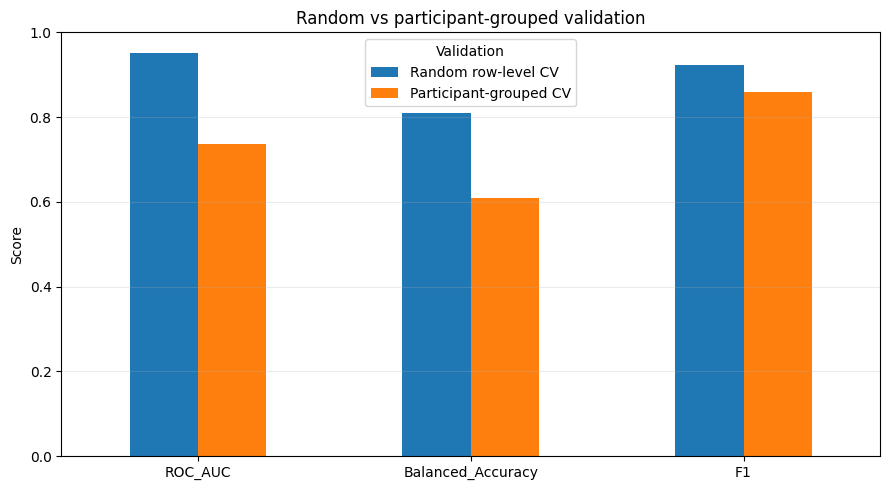


 Random row-level CV
[[ 32  16]
 [  7 140]]
                 precision    recall  f1-score   support

    Control (0)       0.82      0.67      0.74        48
Parkinson's (1)       0.90      0.95      0.92       147

       accuracy                           0.88       195
      macro avg       0.86      0.81      0.83       195
   weighted avg       0.88      0.88      0.88       195


 Participant-grouped CV
[[ 14  34]
 [ 11 136]]
                 precision    recall  f1-score   support

    Control (0)       0.56      0.29      0.38        48
Parkinson's (1)       0.80      0.93      0.86       147

       accuracy                           0.77       195
      macro avg       0.68      0.61      0.62       195
   weighted avg       0.74      0.77      0.74       195



In [19]:
metric_cols = [
    "ROC_AUC", "Average_Precision", "Brier_Score",
    "Balanced_Accuracy", "Precision", "Recall", "F1"
]

if len(SEEDS) == 1:
    print("One seed was used, so this table is a direct comparison, not a multi-seed uncertainty estimate.")
    display(results_df[["Validation"] + metric_cols])
else:
    display(
        results_df.groupby("Validation")[metric_cols]
        .agg(["mean", "std"])
    )

plot_metrics = ["ROC_AUC", "Balanced_Accuracy", "F1"]
plot_data = results_df.set_index("Validation")[plot_metrics].T
ax = plot_data.plot(kind="bar", figsize=(9, 5))
ax.set_ylabel("Score")
ax.set_title("Random vs participant-grouped validation")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Display the confusion matrices for the primary seed.
primary_seed = SEEDS[0]
for validation_name in ["Random row-level CV", "Participant-grouped CV"]:
    prob = oof_predictions[(primary_seed, validation_name)]
    pred = (prob >= THRESHOLD).astype(int)
    print("\n", validation_name)
    print(confusion_matrix(y, pred))
    print(classification_report(y, pred, target_names=["Control (0)", "Parkinson's (1)"], zero_division=0))


## 8. Interpretation

Compare the random and participant-grouped estimates.

- If random validation is noticeably higher, that may indicate that recordings from the same participant make row-level validation overly optimistic.
- If the scores are similar, this dataset may show a smaller validation-design effect under this model and feature set.
- Do not assume that a result from this dataset automatically applies to every medical dataset or to the Kepler catalog.
- The comparison is affected by dataset size, participant count, feature set, model choice, and class balance.

Because the dataset is small and has repeated recordings per participant, report the number of participants as well as the number of recordings. Do not describe this model as clinically validated or suitable for diagnosis.


## 9. Save results

In [20]:
OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)

results_df.to_csv(os.path.join(OUTPUT_DIR, "06_parkinsons_validation_metrics.csv"), index=False)

prediction_output = df[["subject_group", "target"]].copy()
for (seed, validation_name), probabilities in oof_predictions.items():
    safe_name = validation_name.lower().replace(" ", "_").replace("-", "_")
    prediction_output[f"seed_{seed}_{safe_name}_probability"] = probabilities

prediction_output.to_csv(
    os.path.join(OUTPUT_DIR, "06_parkinsons_oof_predictions.csv"),
    index=False
)

print("Saved:")
print(os.path.join(OUTPUT_DIR, "06_parkinsons_validation_metrics.csv"))
print(os.path.join(OUTPUT_DIR, "06_parkinsons_oof_predictions.csv"))


Saved:
/kaggle/working/06_parkinsons_validation_metrics.csv
/kaggle/working/06_parkinsons_oof_predictions.csv
